# Proyek Akhir: Menyelesaikan Permasalahan Perusahaan Edutech

- Nama: Handika R A
- Email: handika.aryatama@gmail.com
- Id Dicoding: handikaaryatama23@gmail.com

## Persiapan

### Menyiapkan library yang dibutuhkan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import joblib
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve


from pathlib import Path
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

### Menyiapkan data yang akan digunakan

Sumber: `data/students_performance.csv` (data Students' Performance).

In [3]:
df = pd.read_csv("data/students_performance.csv", sep=";")

df.head()



,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nacionality,Mothers_qualification,Fathers_qualification,...,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Data Understanding

### 1. Ukuran dan tipe data

In [4]:
df.shape

(4424, 37)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Marital_status                                4424 non-null   int64  
 1   Application_mode                              4424 non-null   int64  
 2   Application_order                             4424 non-null   int64  
 3   Course                                        4424 non-null   int64  
 4   Daytime_evening_attendance                    4424 non-null   int64  
 5   Previous_qualification                        4424 non-null   int64  
 6   Previous_qualification_grade                  4424 non-null   float64
 7   Nacionality                                   4424 non-null   int64  
 8   Mothers_qualification                         4424 non-null   int64  
 9   Fathers_qualification                         4424 non-null   int64  
 10 

**Insight:**
- Data berisi 4424 mahasiswa dan 37 kolom (36 fitur + target `Status`).
- Hanya `Status` yang bertipe teks. Semua kolom lain sudah angka, tetapi banyak di antaranya sebenarnya **kategori yang dikodekan angka** (misalnya `Course`, `Application_mode`, `Gender`).

### 2. Kualitas data

In [6]:
print('Missing value:', df.isnull().sum().sum())
print('Duplikat     :', df.duplicated().sum())

Missing value: 0
Duplikat     : 0


**Insight:** tidak ada missing value maupun baris duplikat, jadi tidak diperlukan proses pembersihan.

### 3. Statistik deskriptif

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital_status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application_mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application_order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime_evening_attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous_qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mothers_qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Fathers_qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


**Insight:**
- `Age_at_enrollment`: rentang 17–70 tahun, median 20 tetapi rata-rata 23,3. Distribusi miring ke kanan karena ada mahasiswa yang mendaftar di usia dewasa.
- `Admission_grade` (skala 0–200): rentang 95–190, rata-rata ~127. Tidak ada nilai di luar skala.
- `Curricular_units_*_grade` (skala 0–20) memiliki `min = 0`. Nilai 0 ini kemungkinan berarti belum ada penilaian, bukan nilai sungguhan (sekitar 16% data semester 1). Penyebab pastinya tidak diketahui dari data, dan dianalisis lebih lanjut di bagian 10.
- `Unemployment_rate`, `Inflation_rate`, dan `GDP` adalah indikator makro, dan hanya memiliki 10 kombinasi nilai unik, sehingga nilainya mengikuti periode, bukan karakteristik individu mahasiswa.

### 4. Pengelompokan kolom
Tipe data saja tidak cukup untuk memisahkan kategorikal dan numerik, karena kode seperti `Course = 9254` tersimpan sebagai angka. Pengelompokan dilakukan manual berdasarkan arti kolom pada `data/README.md`.

In [8]:
df.nunique().sort_values()

Daytime_evening_attendance                        2
Displaced                                         2
Debtor                                            2
Educational_special_needs                         2
International                                     2
Scholarship_holder                                2
Gender                                            2
Tuition_fees_up_to_date                           2
Status                                            3
Marital_status                                    6
Application_order                                 8
Inflation_rate                                    9
Curricular_units_2nd_sem_without_evaluations     10
Unemployment_rate                                10
GDP                                              10
Curricular_units_1st_sem_without_evaluations     11
Course                                           17
Previous_qualification                           17
Application_mode                                 18
Curricular_u

In [9]:
categorical_columns = [
    # kode kategori
    "Marital_status", "Application_mode", "Course", "Previous_qualification",
    "Nacionality", "Mothers_qualification", "Fathers_qualification",
    "Mothers_occupation", "Fathers_occupation",
    # biner (0/1)
    "Daytime_evening_attendance", "Displaced", "Educational_special_needs",
    "Debtor", "Tuition_fees_up_to_date", "Gender", "Scholarship_holder", "International",
]

numerical_columns = [
    c for c in df.columns if c not in categorical_columns + ["Status"]
]

print(len(categorical_columns), len(numerical_columns))
print(set(df.columns) - set(categorical_columns + numerical_columns))

17 19
{'Status'}


**Insight:** 17 kolom kategorikal (9 kode dan 8 biner) dan 19 kolom numerik. Kolom kode tidak boleh dirata-ratakan, sehingga di analisis berikutnya diperlakukan sebagai kategori.

### 5. Distribusi target (`Status`)

Status
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Status
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64
Dropout rate (tanpa Enrolled): 39.1 %


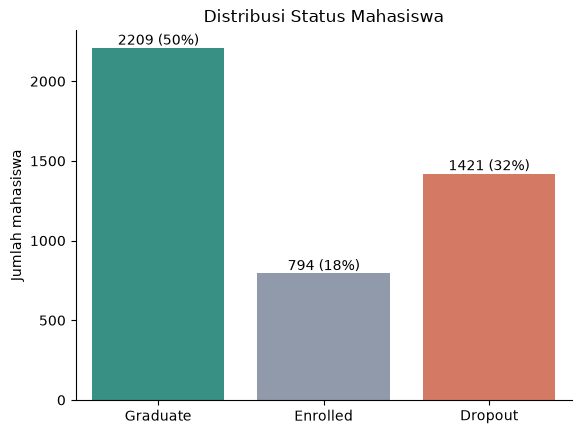

In [10]:
status_counts = df["Status"].value_counts()
print(status_counts)
print((df["Status"].value_counts(normalize=True) * 100).round(1))

colors = {"Graduate": "#2a9d8f", "Enrolled": "#8d99ae", "Dropout": "#e76f51"}
resolved = df[df["Status"] != "Enrolled"]
print("Dropout rate (tanpa Enrolled):", round((resolved["Status"] == "Dropout").mean() * 100, 1), "%")

ax = sns.countplot(data=df, x="Status", order=["Graduate", "Enrolled", "Dropout"],
                   palette=colors, hue="Status", legend=False)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f} ({p.get_height()/len(df):.0%})",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Distribusi Status Mahasiswa")
ax.set_xlabel("")
ax.set_ylabel("Jumlah mahasiswa")
sns.despine()
plt.show()

**Insight:**
- Graduate 49,9%, Dropout 32,1%, dan Enrolled 17,9%. 
- Proporsi 32,1% dihitung terhadap seluruh mahasiswa, termasuk `Enrolled` yang statusnya belum final. Jika hanya membandingkan Dropout dan Graduate, dropout rate-nya 39,1%. Analisis berikutnya memakai penyebut seluruh data (Dropout vs bukan Dropout).
- Hampir 1 dari 3 mahasiswa dropout, angka yang cukup besar bagi institusi.

### 6. Distribusi fitur numerik utama

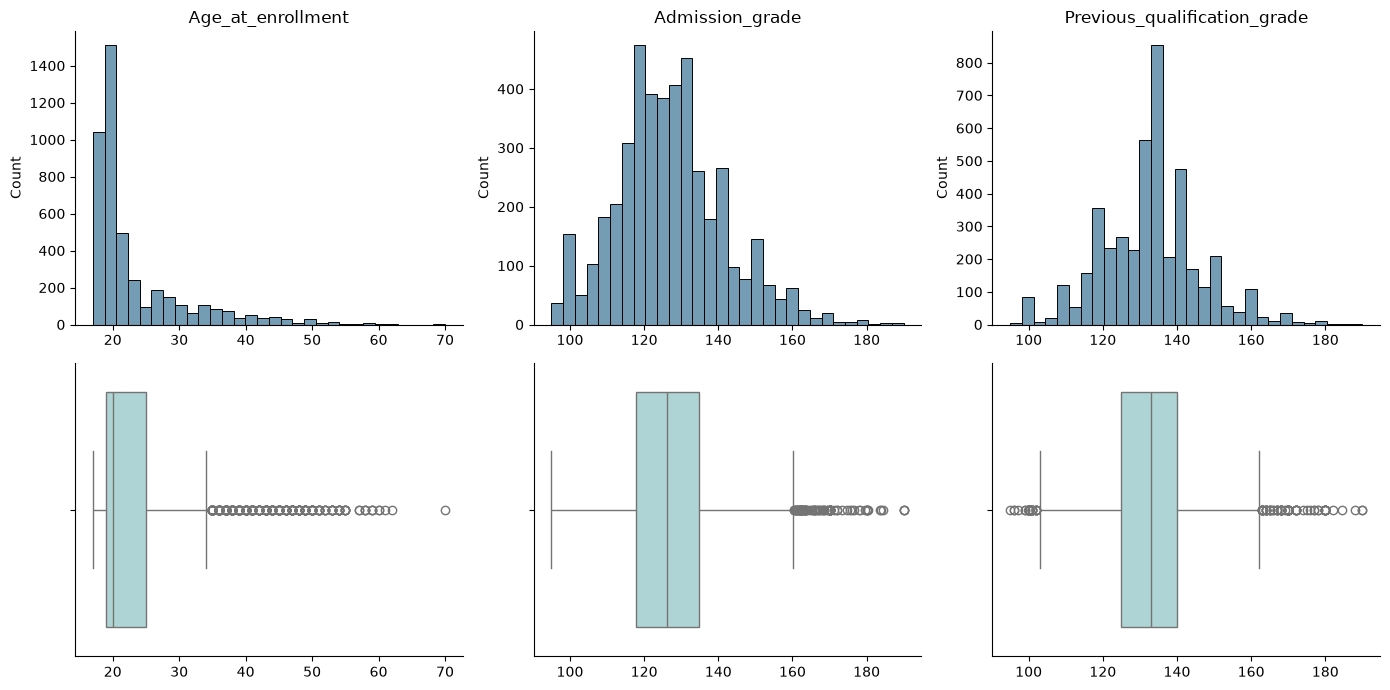

In [11]:
cols = ["Age_at_enrollment", "Admission_grade", "Previous_qualification_grade"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(cols):
    sns.histplot(df[c], bins=30, ax=axes[0, i], color="#457b9d")
    axes[0, i].set_title(c)
    axes[0, i].set_xlabel("")
    sns.boxplot(x=df[c], ax=axes[1, i], color="#a8dadc")
    axes[1, i].set_xlabel("")
plt.tight_layout()
sns.despine()
plt.show()

**Insight:**
- `Age_at_enrollment` sangat miring ke kanan, mayoritas berusia di bawah 25 tahun dengan banyak outlier di atas 30 tahun. Outlier ini adalah mahasiswa dewasa yang valid, bukan error, sehingga dipertahankan.
- `Admission_grade` dan `Previous_qualification_grade` berbentuk lonceng dan relatif simetris, dengan sedikit outlier di nilai tinggi.

### 7. Dropout rate menurut fitur kategorikal

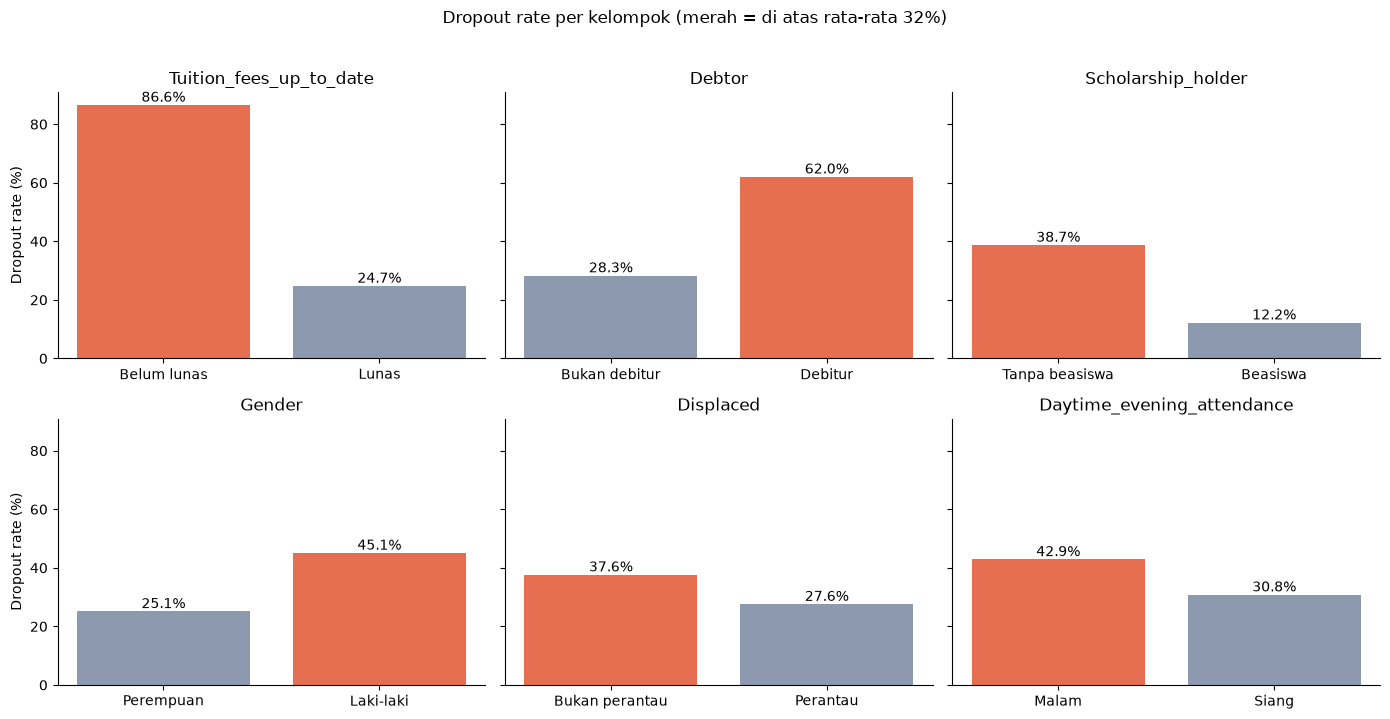

Debitur               0    1
Uang kuliah lunas           
0                   282  246
1                  3639  257


In [12]:
df["is_dropout"] = (df["Status"] == "Dropout").astype(int)

binary_cols = ["Tuition_fees_up_to_date", "Debtor", "Scholarship_holder",
               "Gender", "Displaced", "Daytime_evening_attendance"]
labels = {
    "Tuition_fees_up_to_date": ("Belum lunas", "Lunas"),
    "Debtor": ("Bukan debitur", "Debitur"),
    "Scholarship_holder": ("Tanpa beasiswa", "Beasiswa"),
    "Gender": ("Perempuan", "Laki-laki"),
    "Displaced": ("Bukan perantau", "Perantau"),
    "Daytime_evening_attendance": ("Malam", "Siang"),
}
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, c in zip(axes.flat, binary_cols):
    rate = df.groupby(c)["is_dropout"].mean() * 100
    bars = ax.bar(labels[c], rate.values,
                  color=["#e76f51" if v > df["is_dropout"].mean() * 100 else "#8d99ae" for v in rate.values])
    for b in bars:
        ax.annotate(f"{b.get_height():.1f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom")
    ax.set_title(c)
axes[0, 0].set_ylabel("Dropout rate (%)")
axes[1, 0].set_ylabel("Dropout rate (%)")
fig.suptitle("Dropout rate per kelompok (merah = di atas rata-rata 32%)", y=1.02)
plt.tight_layout()
sns.despine()
plt.show()

print(pd.crosstab(df["Tuition_fees_up_to_date"], df["Debtor"],
                  rownames=["Uang kuliah lunas"], colnames=["Debitur"]))

**Insight:**
- **Uang kuliah belum lunas**: dropout rate 86,6% vs 24,7% yang lunas. Ini pembeda terkuat di antara fitur kategorikal.
- **Debitur**: 62,0% dropout vs 28,3% non-debitur.
- **Penerima beasiswa**: hanya 12,2% dropout vs 38,7% tanpa beasiswa.
- **Laki-laki** dropout 45,1% vs perempuan 25,1%.
- Dari 528 mahasiswa yang uang kuliahnya belum lunas, 246 orang (47%) juga tercatat sebagai debitur. Dengan demikian, keduanya tidak dapat dipandang sebagai dua kelompok yang sepenuhnya terpisah.
- Perantau (`Displaced`) justru sedikit lebih rendah dropout-nya (27,6% vs 37,6%), dan kelas malam lebih tinggi (42,9% vs 30,8%) walau jumlahnya sedikit.

### 8. Dropout rate menurut program studi dan usia

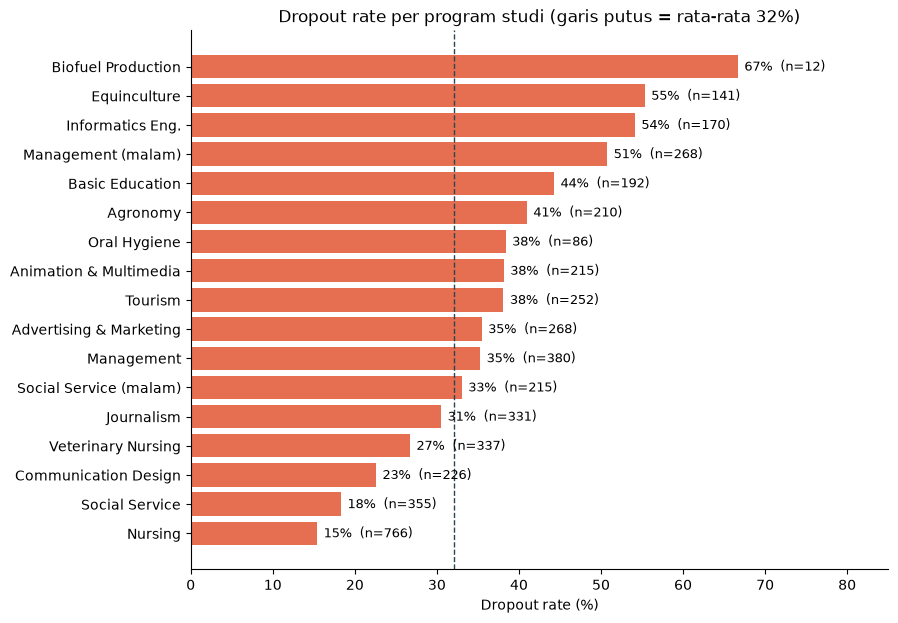

,dropout_rate_%,n
Age_at_enrollment,,
<=19,21.0,1952
20-22,25.9,1095
23-25,43.4,332
26-30,59.8,383
>30,53.6,662


In [13]:
course_names = {
    33: "Biofuel Production", 171: "Animation & Multimedia", 8014: "Social Service (malam)",
    9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing",
    9119: "Informatics Eng.", 9130: "Equinculture", 9147: "Management",
    9238: "Social Service", 9254: "Tourism", 9500: "Nursing", 9556: "Oral Hygiene",
    9670: "Advertising & Marketing", 9773: "Journalism", 9853: "Basic Education",
    9991: "Management (malam)",
}
stat = df.groupby("Course")["is_dropout"].agg(["mean", "count"])
stat.index = stat.index.map(course_names)
stat = stat.sort_values("mean")
stat["mean"] *= 100

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(stat.index, stat["mean"], color="#e76f51")
for y, (m, n) in enumerate(zip(stat["mean"], stat["count"])):
    ax.text(m + 0.8, y, f"{m:.0f}%  (n={n})", va="center", fontsize=9)
ax.axvline(df["is_dropout"].mean() * 100, color="#264653", ls="--", lw=1)
ax.set_title("Dropout rate per program studi (garis putus = rata-rata 32%)")
ax.set_xlabel("Dropout rate (%)")
ax.set_xlim(0, 85)
sns.despine()
plt.show()

age_group = pd.cut(df["Age_at_enrollment"], [0, 19, 22, 25, 30, 100],
                   labels=["<=19", "20-22", "23-25", "26-30", ">30"])
age_stat = df.groupby(age_group, observed=True)["is_dropout"].agg(["mean", "count"])
age_stat["mean"] = (age_stat["mean"] * 100).round(1)
age_stat.columns = ["dropout_rate_%", "n"]
age_stat

**Insight:**
- Dropout tertinggi: Informatics Engineering (54%), Equinculture (55%), dan Management kelas malam (51%). Program Biofuel (67%) hanya berisi 12 mahasiswa sehingga tidak bisa disimpulkan.
- Dropout terendah: Nursing (15%) dan Social Service (18%).
- Usia: dropout rate naik tajam setelah 22 tahun, dari 21% (<=19) menjadi sekitar 60% di kelompok 26–30 tahun. Kelompok >30 tahun hanya sekitar 15% data, sehingga angkanya kurang stabil dibanding kelompok lain.

### 9. Kinerja akademik vs Status

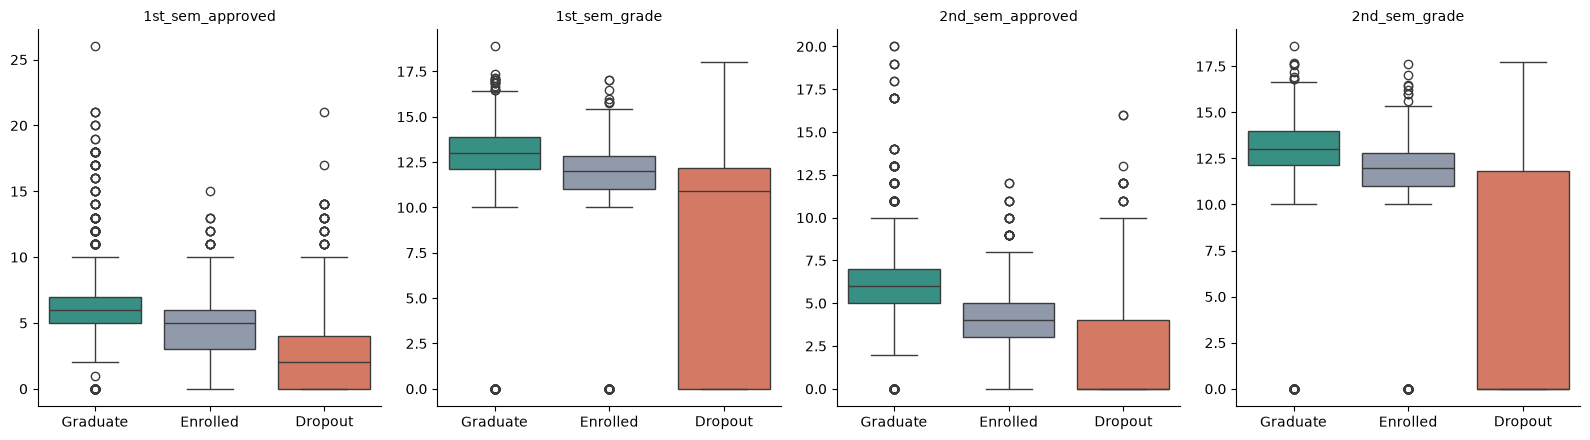

,Curricular_units_1st_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade
Status,,,,
Dropout,2.55,7.26,1.94,5.90
Enrolled,4.32,11.13,4.06,11.12
Graduate,6.23,12.64,6.18,12.70


In [14]:
perf = ["Curricular_units_1st_sem_approved", "Curricular_units_1st_sem_grade",
        "Curricular_units_2nd_sem_approved", "Curricular_units_2nd_sem_grade"]
order = ["Graduate", "Enrolled", "Dropout"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, c in zip(axes, perf):
    sns.boxplot(data=df, x="Status", y=c, order=order, palette=colors,
                hue="Status", legend=False, ax=ax)
    ax.set_title(c.replace("Curricular_units_", ""), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
sns.despine()
plt.show()

df.groupby("Status")[perf].mean().round(2)

**Insight:**
- Mahasiswa dropout rata-rata hanya meluluskan **2,5 mata kuliah** di semester 1 dan **1,9** di semester 2, sedangkan graduate meluluskan sekitar **6,2** di kedua semester.
- Rata-rata nilai semester 2 dropout 5,9 vs graduate 12,7.
- Di semester 2, 51% mahasiswa dropout tidak meluluskan satu mata kuliah pun (graduate: 3%). Ini sinyal risiko yang bisa dipantau (lihat bagian 10).

### 10. Sinyal peringatan dini: nilai semester 1 bernilai 0

In [15]:
zero = df["Curricular_units_1st_sem_grade"] == 0
print(f"Mahasiswa dengan nilai sem-1 = 0     : {zero.mean():.1%} ({zero.sum()} orang)")
print(f"  di antaranya tidak mengambil MK    : {(df.loc[zero, 'Curricular_units_1st_sem_enrolled'] == 0).mean():.1%}")
print(f"Dropout rate nilai sem-1 = 0         : {df.loc[zero, 'is_dropout'].mean():.1%}")
print(f"Dropout rate nilai sem-1 > 0         : {df.loc[~zero, 'is_dropout'].mean():.1%}")

no_pass = df["Curricular_units_2nd_sem_approved"] == 0
print()
print("Persentase mahasiswa tanpa satu pun MK lulus di semester 2, per Status:")
print((no_pass.groupby(df["Status"]).mean() * 100).round(1))

Mahasiswa dengan nilai sem-1 = 0     : 16.2% (718 orang)
  di antaranya tidak mengambil MK    : 25.1%
Dropout rate nilai sem-1 = 0         : 79.4%
Dropout rate nilai sem-1 > 0         : 23.0%

Persentase mahasiswa tanpa satu pun MK lulus di semester 2, per Status:
Status
Dropout     51.2
Enrolled     8.6
Graduate     3.4
Name: Curricular_units_2nd_sem_approved, dtype: float64


**Insight:**
- 16,2% mahasiswa memiliki nilai semester 1 sama dengan 0. Hanya sekitar seperempat dari mereka yang tidak mengambil mata kuliah, jadi sebagian besar tetap terdaftar tetapi tidak memiliki nilai.
- Dropout rate kelompok ini **79,4%**, jauh di atas 23,0% pada kelompok lainnya.
- Di semester 2, sekitar 51% mahasiswa dropout tidak lulus satu mata kuliah pun, dibanding 3% pada graduate.
- Kedua indikator ini bisa dipantau institusi per semester sebagai sinyal peringatan dini.

### 11. Korelasi fitur numerik dengan dropout

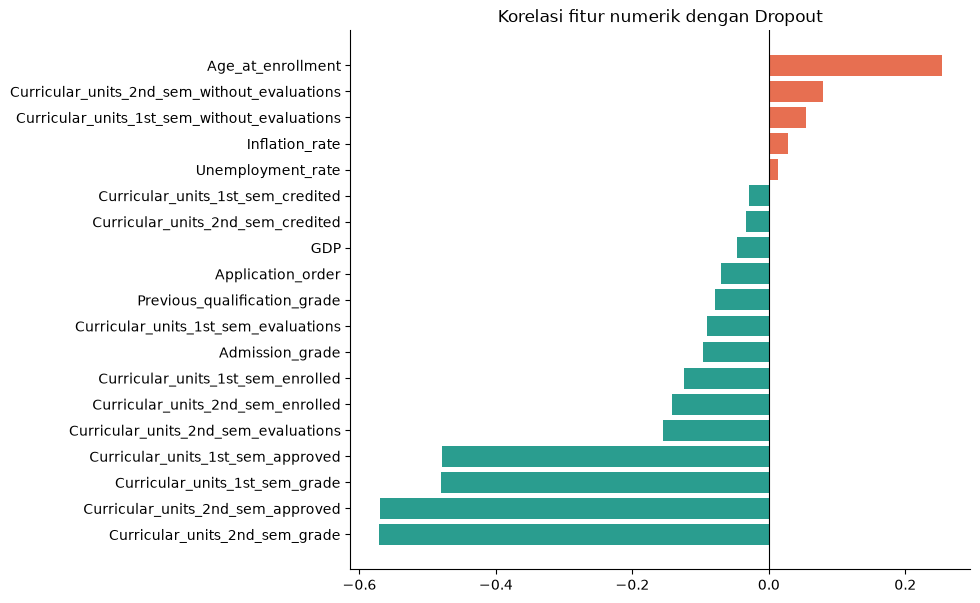

(Curricular_units_1st_sem_without_evaluations    0.054
 Curricular_units_2nd_sem_without_evaluations    0.080
 Age_at_enrollment                               0.254
 Name: is_dropout, dtype: float64,
 Curricular_units_2nd_sem_grade      -0.572
 Curricular_units_2nd_sem_approved   -0.570
 Curricular_units_1st_sem_grade      -0.481
 Curricular_units_1st_sem_approved   -0.479
 Name: is_dropout, dtype: float64)

In [16]:
corr = df[numerical_columns + ["is_dropout"]].corr()["is_dropout"].drop("is_dropout").sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(corr.index, corr.values, color=["#2a9d8f" if v < 0 else "#e76f51" for v in corr.values])
ax.set_title("Korelasi fitur numerik dengan Dropout")
ax.axvline(0, color="black", lw=0.8)
sns.despine()
plt.show()

corr.round(3).tail(3), corr.round(3).head(4)

**Insight:**
- Korelasi negatif terkuat: nilai dan jumlah mata kuliah lulus pada semester 2 (sekitar -0,57) dan semester 1 (sekitar -0,48). Semakin banyak mata kuliah lulus, semakin kecil risiko dropout.
- Korelasi positif terkuat: `Age_at_enrollment` (+0,25).
- Indikator makro (`Unemployment_rate`, `Inflation_rate`, `GDP`) hampir tidak berkorelasi (|r| < 0,05), jadi bukan faktor penting.

### 12. Korelasi antar fitur kinerja akademik

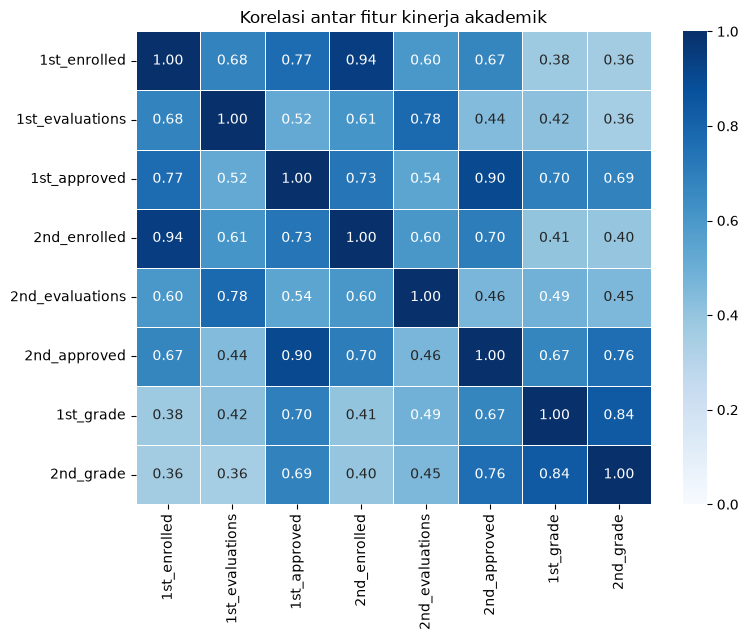

In [17]:
sem_cols = [c for c in df.columns if c.startswith("Curricular_units_") and "grade" not in c and "credited" not in c and "without" not in c] + \
           ["Curricular_units_1st_sem_grade", "Curricular_units_2nd_sem_grade"]
short = [c.replace("Curricular_units_", "").replace("_sem", "") for c in sem_cols]
cm = df[sem_cols].corr()
cm.index = cm.columns = short

plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=0.5)
plt.title("Korelasi antar fitur kinerja akademik")
plt.tight_layout()
plt.show()

**Insight:** fitur semester 1 dan semester 2 sangat berkorelasi (jumlah mata kuliah diambil semester 1 vs 2 = 0,94, jumlah lulus semester 1 vs 2 = 0,90, sedangkan diambil vs lulus dalam satu semester 0,70–0,77). Fitur-fitur ini membawa informasi yang mirip, sehingga di tahap modeling perlu hati-hati menafsirkan pentingnya masing-masing fitur.

### Kesimpulan 

Data bersih (tanpa missing value dan duplikat), dengan 32% mahasiswa dropout. Tiga faktor teratas yang berhubungan dengan dropout:

1. **Kinerja akademik** adalah sinyal terkuat. Mahasiswa dropout rata-rata hanya lulus 2,5 mata kuliah di semester 1 (graduate: 6,2). Mahasiswa dengan nilai semester 1 = 0 memiliki dropout rate 79%, dan korelasi jumlah mata kuliah lulus dengan dropout sekitar -0,5 sampai -0,6.
2. **Kondisi keuangan**: uang kuliah belum lunas (dropout 87%) dan status debitur (62%). Penerima beasiswa justru jauh lebih rendah (12% vs 39%).
3. **Profil mahasiswa**: mendaftar di usia di atas 22 tahun, laki-laki (45% vs 25% perempuan), dan program studi tertentu seperti Informatics Engineering serta Equinculture (di atas 50%, Nursing hanya 15%).

## Data Preparation / Preprocessing

Pada tahap ini data diubah menjadi bentuk yang siap dipakai model. Data sudah bersih (tanpa missing value dan duplikat), sehingga fokusnya pada pemisahan data berdasarkan status, pembentukan target, pemilihan fitur, pembagian data, dan transformasi.

### 1. Memfilter data dan membentuk target biner
Tujuan sistem adalah memprediksi apakah seorang mahasiswa berpotensi **Dropout** atau **Graduate**. Karena itu:
- Hanya mahasiswa berstatus **Dropout** dan **Graduate** yang dipakai untuk pemodelan, karena hanya keduanya yang memiliki hasil akhir yang jelas.
- Mahasiswa berstatus **Enrolled** statusnya belum final, sehingga **tidak dilibatkan dalam training maupun evaluasi**. Mereka dipisahkan (`df_enrolled`) untuk dipakai sebagai data prediksi di masa depan.
- Target biner: **1 = Dropout** dan **0 = Graduate**.

In [18]:
df_model = df[df["Status"].isin(["Dropout", "Graduate"])].copy()
df_enrolled = df[df["Status"] == "Enrolled"].copy()

y = (df_model["Status"] == "Dropout").astype(int)

print("Data pemodelan (Dropout + Graduate):", df_model.shape)
print("Data prediksi masa depan (Enrolled)  :", df_enrolled.shape)
print()
print(y.value_counts().rename({0: "Graduate (0)", 1: "Dropout (1)"}))
print(f"Proporsi Dropout: {y.mean():.1%}")

Data pemodelan (Dropout + Graduate): (3630, 38)
Data prediksi masa depan (Enrolled)  : (794, 38)

Status
Graduate (0)    2209
Dropout (1)     1421
Name: count, dtype: int64
Proporsi Dropout: 39.1%


**Insight:** data pemodelan berisi 3630 mahasiswa: 1421 Dropout (39,1%) dan 2209 Graduate (60,9%). Sebanyak 794 mahasiswa Enrolled dipisahkan untuk prediksi. Proporsi kelas cukup seimbang untuk ditangani dengan `class_weight`, tanpa perlu oversampling.

### 2. Memilih fitur
Keputusan: model dipakai untuk **deteksi dini setelah semester 1 selesai**. Karena itu:
- Kolom `Status` dan `is_dropout` dibuang dari fitur karena merupakan target (mencegah *data leakage*).
- Seluruh kolom semester 2 (`Curricular_units_2nd_sem_*`) dibuang karena baru tersedia setelah semester 2 berjalan, saat sebagian mahasiswa sudah terlanjur dropout.
- Fitur pendaftaran dan semester 1 dipertahankan.

In [19]:
second_sem_cols = [c for c in df.columns if "_2nd_sem_" in c]
drop_cols = ["Status", "is_dropout"] + second_sem_cols

X = df_model.drop(columns=drop_cols, errors="ignore")
X_enrolled = df_enrolled.drop(columns=drop_cols, errors="ignore")

print("Kolom semester 2 yang dibuang:", len(second_sem_cols))
print("Jumlah fitur:", X.shape[1])

Kolom semester 2 yang dibuang: 6
Jumlah fitur: 30


### 3. Membuat fitur turunan
Tingkat kelulusan semester 1 (`approval_rate_1st_sem`) = mata kuliah lulus dibagi mata kuliah diambil. Fitur ini menunjukkan seberapa besar bagian beban studi yang berhasil diselesaikan, dan lebih adil dibanding jumlah lulus saja karena beban tiap mahasiswa berbeda. Jika tidak mengambil mata kuliah (pembagi 0), nilainya diisi 0.

In [20]:
def add_approval_rate(frame):
    enrolled = frame["Curricular_units_1st_sem_enrolled"].replace(0, np.nan)
    frame["approval_rate_1st_sem"] = (frame["Curricular_units_1st_sem_approved"] / enrolled).fillna(0)
    return frame

X = add_approval_rate(X)
X_enrolled = add_approval_rate(X_enrolled)

X.groupby(y)["approval_rate_1st_sem"].mean().rename({0: "Graduate", 1: "Dropout"})

Status
Graduate    0.903223
Dropout     0.383994
Name: approval_rate_1st_sem, dtype: float64

**Insight:** rata-rata tingkat kelulusan semester 1 adalah 90% pada Graduate dan hanya 38% pada Dropout, sehingga fitur turunan ini informatif.

### 4. Membagi data latih dan data uji
Data pemodelan (Dropout dan Graduate) dibagi 80% latih dan 20% uji. `stratify=y` menjaga proporsi dropout sama di kedua bagian, dan `random_state` membuat hasil dapat diulang. Pembagian dilakukan **sebelum** encoding dan scaling agar tidak ada kebocoran informasi dari data uji. Data Enrolled tidak ikut dibagi karena disimpan terpisah untuk prediksi.

In [21]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print(f"Proporsi Dropout - latih: {y_train.mean():.1%} | uji: {y_test.mean():.1%}")

Data latih: (2904, 31) | Data uji: (726, 31)
Proporsi Dropout - latih: 39.2% | uji: 39.1%


### 5. Menentukan transformasi fitur
Fitur dibagi menjadi tiga kelompok berdasarkan hasil Data Understanding:

| Kelompok | Perlakuan | Alasan |
|---|---|---|
| Nominal (kode kategori) | One-hot encoding | Angka hanya label, urutannya tidak bermakna |
| Numerik | Standardisasi | Skala antar kolom berbeda (nilai 0-200, usia, jumlah mata kuliah) |
| Biner (0/1) | Dibiarkan | Sudah dalam bentuk angka yang bermakna |

Transformasi dibungkus dalam `ColumnTransformer` agar nantinya menjadi satu `Pipeline` bersama model. Dengan cara ini, preprocessing dipelajari hanya dari data latih dan otomatis ikut diterapkan pada data baru di aplikasi Streamlit.

In [22]:


binary_features = [
    "Daytime_evening_attendance", "Displaced", "Educational_special_needs",
    "Debtor", "Tuition_fees_up_to_date", "Gender", "Scholarship_holder", "International",
]
nominal_features = [c for c in categorical_columns if c not in binary_features]
numeric_features = [c for c in X.columns if c not in nominal_features + binary_features]

preprocessor = ColumnTransformer([
    ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
    ("numeric", StandardScaler(), numeric_features),
    ("binary", "passthrough", binary_features),
])

print("Nominal:", len(nominal_features), "| Numerik:", len(numeric_features), "| Biner:", len(binary_features))
print("Total  :", len(nominal_features) + len(numeric_features) + len(binary_features), "| Kolom X:", X.shape[1])

Nominal: 9 | Numerik: 14 | Biner: 8
Total  : 31 | Kolom X: 31


Pengecekan hasil transformasi. `fit` hanya pada data latih, lalu `transform` pada data uji.

In [23]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Data latih setelah transformasi:", X_train_prepared.shape)
print("Data uji setelah transformasi  :", X_test_prepared.shape)

Data latih setelah transformasi: (2904, 222)
Data uji setelah transformasi  : (726, 222)


**Insight:** setelah one-hot encoding, jumlah kolom bertambah banyak karena kolom kode seperti `Course` dan `Application_mode` dipecah per kategori. Data latih dan data uji memiliki jumlah kolom yang sama.

## Modeling

### 1. Membandingkan tiga model
Tiga model dengan karakter berbeda dibandingkan pada target Dropout (1) vs Graduate (0):
- **Logistic Regression**: baseline linear yang mudah dijelaskan.
- **Random Forest**: kumpulan pohon keputusan, mampu menangkap hubungan non-linear.
- **Histogram Gradient Boosting**: pohon yang dilatih bertahap untuk memperbaiki kesalahan sebelumnya, biasanya kuat pada data tabular.

Ketiganya memakai `class_weight="balanced"` agar kelas Dropout (kelas minoritas) tidak diabaikan. Setiap model dibungkus dalam `Pipeline` bersama `preprocessor`, sehingga encoding dan scaling dipelajari ulang hanya dari data latih pada setiap lipatan cross-validation.

In [24]:

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced",
                                                             random_state=42),
}

pipelines = {
    name: Pipeline([("preprocess", preprocessor), ("model", model)])
    for name, model in models.items()
}
list(pipelines)

['Logistic Regression', 'Random Forest', 'Hist Gradient Boosting']

### 2. Cross-validation pada data latih
Setiap model diuji dengan 5-fold *stratified* cross-validation **hanya pada data latih**. Metrik dihitung untuk kelas Dropout (kelas 1):
- **Recall**: dari semua mahasiswa dropout sebenarnya, berapa persen yang berhasil terdeteksi.
- **Precision**: dari semua yang diprediksi dropout, berapa persen yang benar.
- **F1**: gabungan keduanya.
- **ROC-AUC**: kemampuan memisahkan dua kelas tanpa bergantung pada ambang keputusan.

Skor latih ikut ditampilkan untuk mendeteksi overfitting.

In [25]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["recall", "precision", "f1", "roc_auc"]

rows = {}
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True)
    rows[name] = {
        "recall": res["test_recall"].mean(),
        "precision": res["test_precision"].mean(),
        "f1": res["test_f1"].mean(),
        "f1_std": res["test_f1"].std(),
        "roc_auc": res["test_roc_auc"].mean(),
        "f1_latih": res["train_f1"].mean(),
    }

cv_results = pd.DataFrame(rows).T.round(3)
cv_results

,recall,precision,f1,f1_std,roc_auc,f1_latih
Logistic Regression,0.843,0.848,0.846,0.008,0.932,0.874
Random Forest,0.826,0.871,0.848,0.016,0.933,1.000
Hist Gradient Boosting,0.819,0.877,0.847,0.016,0.930,0.998


**Insight:**
- Ketiga model berkinerja hampir sama pada data validasi: F1 sekitar 0,85 dan ROC-AUC sekitar 0,93. **Logistic Regression** memiliki recall Dropout tertinggi (0,84).
- **Random Forest** dan **Hist Gradient Boosting** menunjukkan *overfitting*: F1 pada data latih 1,00 dan 1,00, tetapi pada validasi hanya sekitar 0,85. Model kompleks tidak memberi keuntungan.
- Selisih skor latih dan validasi Logistic Regression kecil (0,87 vs 0,85), tanda model stabil dan menggeneralisasi dengan baik.
- Logistic Regression dipilih karena kinerjanya setara, recall tertinggi (prioritas: mendeteksi sebanyak mungkin mahasiswa berisiko), stabil, dan mudah dijelaskan kepada pihak institusi.

### 3. Tuning Logistic Regression
Parameter `C` mengatur kekuatan regularisasi (semakin kecil, semakin kuat model dibatasi). Beberapa nilai dicoba dengan cross-validation pada data latih, dengan F1 kelas Dropout sebagai ukuran.

In [ ]:

grid = GridSearchCV(
    pipelines["Logistic Regression"],
    param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    scoring="f1", cv=cv,
)
grid.fit(X_train, y_train)

print("C terbaik :", grid.best_params_["model__C"])
print(f"F1 validasi: {grid.best_score_:.3f}")
pd.DataFrame(grid.cv_results_)[["param_model__C", "mean_test_score"]].round(3)

**Insight:** `C = 0,3` memberi F1 validasi terbaik (0,849), tetapi selisihnya sangat kecil dibanding `C` antara 0,1 sampai 10 (0,844 sampai 0,847). Artinya model tidak sensitif terhadap parameter ini, dan hanya regularisasi yang terlalu kuat (`C = 0,01`) yang menurunkan kinerja.

### 4. Melatih dan menyimpan model final
Model dengan `C` terbaik (`grid.best_estimator_`) sudah dilatih ulang pada seluruh data latih oleh `GridSearchCV`. Model disimpan bersama daftar kolom masukan dan rata-rata fitur data latih agar bisa dipakai oleh aplikasi Streamlit (termasuk untuk menjelaskan faktor yang memengaruhi prediksi).

In [ ]:


best_model = grid.best_estimator_

Path("model").mkdir(exist_ok=True)
joblib.dump(best_model, "model/dropout_model.joblib")
with open("model/feature_columns.json", "w") as f:
    json.dump(list(X.columns), f, indent=2)

# rata-rata fitur hasil transformasi pada data latih, dipakai aplikasi untuk menjelaskan prediksi
train_means = best_model.named_steps["preprocess"].transform(X_train).mean(axis=0)
with open("model/feature_means.json", "w") as f:
    json.dump(train_means.tolist(), f)

print("Model tersimpan di model/dropout_model.joblib")
print("Jumlah kolom masukan:", len(X.columns))

## Evaluation

Model terpilih (Logistic Regression hasil tuning) kini diuji pada **data uji**, data yang belum pernah dipakai untuk melatih maupun memilih model. Hasil di sini adalah perkiraan kinerja pada mahasiswa baru.

### 1. Metrik pada data uji
Kelas yang menjadi perhatian adalah **Dropout (1)**. Sebagai pembanding, model asal-asalan yang selalu menebak "Graduate" disertakan.

In [ ]:
y_pred = best_model.predict(X_test)
y_score = best_model.predict_proba(X_test)[:, 1]

metrics = pd.Series({
    "Akurasi": accuracy_score(y_test, y_pred),
    "Precision (Dropout)": precision_score(y_test, y_pred),
    "Recall (Dropout)": recall_score(y_test, y_pred),
    "F1 (Dropout)": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_score),
}).round(3)
print(metrics.to_string())
print(f"\nPembanding - akurasi jika selalu menebak 'Graduate': {(y_test == 0).mean():.3f}\n")
print(classification_report(y_test, y_pred, target_names=["Graduate", "Dropout"]))

**Insight:**
- Pada data uji (hanya Dropout dan Graduate), model mencapai **recall Dropout 0,90**, precision 0,82, F1 0,86, dan ROC-AUC 0,95.
- Akurasi 0,88 jauh di atas pembanding 0,61 (selalu menebak "Graduate"), sehingga model benar-benar menangkap pola, bukan sekadar mengikuti kelas mayoritas.
- Hasilnya konsisten dengan cross-validation pada data latih (recall 0,84 dan F1 0,85), sehingga tidak ada tanda overfitting.

### 2. Confusion matrix dan kurva ROC

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Graduate", "Dropout"],
    cmap="Blues", colorbar=False, ax=axes[0],
)
axes[0].set_title("Confusion matrix (data uji)")

fpr, tpr, _ = roc_curve(y_test, y_score)
axes[1].plot(fpr, tpr, color="#e76f51", lw=2, label=f"Model (AUC = {roc_auc_score(y_test, y_score):.2f})")
axes[1].plot([0, 1], [0, 1], "--", color="#8d99ae", label="Tebakan acak")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("Kurva ROC")
axes[1].legend(loc="lower right")

plt.tight_layout()
sns.despine()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Terdeteksi benar (TP): {tp} | Terlewat (FN): {fn} | Alarm palsu (FP): {fp} | Benar Graduate (TN): {tn}")

**Insight:**
- Dari 284 mahasiswa yang sebenarnya dropout, **255 terdeteksi** (90%) dan 29 terlewat.
- Model menandai 310 mahasiswa sebagai berisiko, dan 255 di antaranya benar (82%). Sisanya 55 adalah alarm palsu.
- ROC-AUC 0,95 berarti, jika diambil satu mahasiswa Dropout dan satu Graduate secara acak, model memberi skor risiko lebih tinggi kepada yang Dropout pada 95% kasus.

### 3. Memilih ambang keputusan
Secara bawaan, mahasiswa diprediksi dropout jika skor ≥ 0,5. Ambang ini bisa digeser sesuai kebutuhan institusi: ambang lebih rendah menjaring lebih banyak mahasiswa berisiko (recall naik) tetapi lebih banyak alarm palsu (precision turun).

In [ ]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (y_score >= t).astype(int)
    rows.append({
        "ambang": t,
        "recall": recall_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "ditandai_berisiko_%": pred.mean() * 100,
        "terlewat": int(((pred == 0) & (y_test == 1)).sum()),
        "alarm_palsu": int(((pred == 1) & (y_test == 0)).sum()),
    })
threshold_table = pd.DataFrame(rows).set_index("ambang").round(3)
threshold_table

**Insight:**
- Ambang **0,5** memberi keseimbangan yang baik (F1 0,859): 90% dropout terdeteksi, dengan 29 terlewat dan 55 alarm palsu. Ambang 0,6 dan 0,7 memberi F1 sedikit lebih tinggi (0,865 dan 0,866), tetapi dengan recall lebih rendah.
- Menurunkan ambang ke **0,3** mendeteksi 92% dropout (terlewat turun dari 29 menjadi 22), tetapi alarm palsu naik dari 55 menjadi 109 dan 51% mahasiswa ditandai. Artinya, tambahan 7 mahasiswa dropout yang terjaring harus dibayar 54 alarm palsu tambahan.
- Menaikkan ambang ke 0,7 menghasilkan alarm paling sedikit (25), tetapi 48 mahasiswa dropout terlewat.
- Pilihan ambang bergantung pada biaya pendampingan: jika konseling murah dan melewatkan mahasiswa sangat merugikan, ambang yang lebih rendah layak dipertimbangkan. Ambang 0,5 dipakai sebagai nilai awal.
- Skor model bukan probabilitas sebenarnya, karena pelatihan memakai `class_weight="balanced"` yang menaikkan skor kelas Dropout. Skor lebih tepat dipakai untuk mengurutkan prioritas.

### 4. Prediksi untuk mahasiswa Enrolled (data masa depan)
Mahasiswa `Enrolled` tidak dipakai saat pelatihan maupun evaluasi. Model kini diterapkan pada mereka untuk memperkirakan siapa yang berpotensi Dropout dan perlu didampingi lebih awal. Level risiko: Tinggi (skor ≥ 0,5), Sedang (0,3 sampai < 0,5), Rendah (< 0,3).

In [ ]:
enrolled_score = best_model.predict_proba(X_enrolled)[:, 1]
enrolled_risk = pd.cut(enrolled_score, [-0.01, 0.3, 0.5, 1.01], labels=["Rendah", "Sedang", "Tinggi"], right=False)

print("Jumlah mahasiswa Enrolled:", len(X_enrolled))
print(pd.Series(enrolled_risk).value_counts().reindex(["Tinggi", "Sedang", "Rendah"]).to_string())
print(f"Ditandai berisiko dropout (skor >= 0,5): {(enrolled_score >= 0.5).mean():.1%}")

**Insight:**
- Dari 794 mahasiswa Enrolled, **420 (53%) berlevel risiko Tinggi**, 129 Sedang, dan 245 Rendah.
- Kelompok risiko Tinggi adalah kandidat utama untuk pendampingan dini. Statusnya belum final sehingga data tidak memungkinkan kita memastikan berapa dari mereka yang akhirnya benar-benar dropout. Hasil ini adalah perkiraan, bukan fakta.

### 5. Fitur yang paling berpengaruh
Pada Logistic Regression, koefisien menunjukkan arah dan kekuatan pengaruh fitur. Koefisien positif menaikkan skor risiko, negatif menurunkannya. Fitur numerik sudah distandardisasi sehingga koefisiennya dapat dibandingkan. Yang ditampilkan hanya fitur numerik dan biner, karena koefisien kategori hasil one-hot (misalnya satu kode kewarganegaraan tertentu) bisa sangat besar hanya karena anggotanya sedikit, sehingga tidak stabil untuk ditafsirkan.

In [ ]:
names = best_model.named_steps["preprocess"].get_feature_names_out()
coef = pd.Series(best_model.named_steps["model"].coef_[0], index=names)

coef = coef[coef.index.str.startswith(("numeric__", "binary__"))]
coef.index = coef.index.str.split("__").str[1]
coef = coef.sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(coef.index, coef.values, color=["#2a9d8f" if v < 0 else "#e76f51" for v in coef.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Koefisien fitur numerik dan biner (merah menaikkan risiko, hijau menurunkan)")
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Faktor yang paling **menurunkan** risiko: uang kuliah lunas tepat waktu dan jumlah mata kuliah lulus semester 1, disusul penerima beasiswa.
- Faktor yang **menaikkan** risiko: status debitur, jenis kelamin laki-laki, dan jumlah mata kuliah yang diambil. Yang terakhir naik karena, pada jumlah mata kuliah lulus yang sama, semakin banyak mata kuliah diambil berarti semakin kecil porsi yang diselesaikan.
- Pola ini sejalan dengan Data Understanding. Satu perbedaan: status perantau (`Displaced`) menaikkan risiko di model, padahal secara tunggal dropout rate perantau justru lebih rendah. Setelah faktor lain diperhitungkan arahnya berbalik, tanda bahwa hubungan awal dipengaruhi faktor lain.
- Fitur saling berkorelasi (misalnya jumlah diambil dan lulus), sehingga koefisien per fitur harus dibaca hati-hati dan tidak berarti sebab-akibat.

### Kesimpulan Evaluasi

Model Logistic Regression dilatih hanya pada mahasiswa berstatus Dropout dan Graduate (target 1 = Dropout, 0 = Graduate), dan mampu mengenali mahasiswa berisiko dropout setelah semester 1 dengan baik pada data uji yang belum pernah dilihat: **recall 0,90, precision 0,82, F1 0,86, ROC-AUC 0,95**. Sekitar 9 dari 10 mahasiswa yang akan dropout terdeteksi, dan 82% dari yang ditandai memang dropout. Mahasiswa Enrolled (794 orang) tidak ikut pelatihan dan dipakai sebagai data prediksi: 420 di antaranya berlevel risiko Tinggi.